# ДЗ до теми 6: класифікація зображень Intel Image Classification

Студент: Фарід Джафарлі

У наборі даних близько 25 000 фотографій природних сцен розміром 150 на 150 пікселів. Кожна належить до одного з 6 класів: buildings, forest, glacier, mountain, sea, street. Задача: навчити модель, яка визначає клас нового зображення.

Я використовую варіант B із завдання, transfer learning: беру ResNet18, яку вже навчили на ImageNet, і доналаштовую її на ці 6 класів.

## 1. Імпорт бібліотек

In [1]:
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

NUM_WORKERS = min(4, os.cpu_count() or 1)
MP_CONTEXT = 'forkserver' if sys.platform == 'darwin' else None  # faster worker start on macOS
print('Пристрій:', DEVICE)

Пристрій: mps


## 2. Підготовка даних

Дані вже поділені на навчальну (seg_train) і тестову (seg_test) частини. Від навчальної я відділяю 15% для валідації. Поділ стратифікований, тобто в обох частинах однакова частка кожного класу.

In [2]:
def find_split(root, name):
    # the Kaggle archive nests every split twice: seg_train/seg_train/<class>
    nested = root / name / name
    return nested if nested.exists() else root / name


DATA_ROOT = Path('data')
if not (DATA_ROOT / 'seg_train').exists():
    import kagglehub
    DATA_ROOT = Path(kagglehub.dataset_download('puneet6060/intel-image-classification'))

TRAIN_DIR = find_split(DATA_ROOT, 'seg_train')
TEST_DIR = find_split(DATA_ROOT, 'seg_test')

full_train = datasets.ImageFolder(TRAIN_DIR)
test_files = datasets.ImageFolder(TEST_DIR)
CLASSES = full_train.classes

train_idx, val_idx = train_test_split(np.arange(len(full_train)), test_size=0.15,
                                      stratify=full_train.targets, random_state=SEED)

targets = np.array(full_train.targets)
pd.DataFrame({
    'train': np.bincount(targets[train_idx], minlength=6),
    'validation': np.bincount(targets[val_idx], minlength=6),
    'test': np.bincount(test_files.targets, minlength=6),
}, index=CLASSES)

,train,validation,test
buildings,1862,329,437
forest,1930,341,474
glacier,2043,361,553
mountain,2135,377,525
sea,1933,341,510
street,2025,357,501


## 3. Попередня обробка зображень

- Розмір змінюю до 224 на 224, бо ResNet18 навчали саме на зображеннях такого розміру. До того ж частина картинок у наборі має не 150 на 150, а трохи інший розмір.
- Нормалізую кольори середнім і стандартним відхиленням ImageNet, бо модель звикла до вхідних даних саме в такому масштабі.
- В основній моделі аугментацій немає. Аугментацію я пробую окремо в розділі 9.

In [3]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

BATCH_SIZE = 64


def make_loader(dataset, shuffle):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      multiprocessing_context=MP_CONTEXT, persistent_workers=True,
                      generator=torch.Generator().manual_seed(SEED))


train_ds = Subset(datasets.ImageFolder(TRAIN_DIR, eval_tf), train_idx)
val_ds = Subset(datasets.ImageFolder(TRAIN_DIR, eval_tf), val_idx)
test_ds = datasets.ImageFolder(TEST_DIR, eval_tf)

train_loader = make_loader(train_ds, shuffle=True)
train_eval_loader = make_loader(train_ds, shuffle=False)
val_loader = make_loader(val_ds, shuffle=False)
test_loader = make_loader(test_ds, shuffle=False)
print('train:', len(train_ds), 'validation:', len(val_ds), 'test:', len(test_ds))

train: 11928 validation: 2106 test: 3000


## 4. Модель

ResNet18 уже вміє знаходити на фото краї, текстури, форми й об'єкти, бо її навчали на мільйоні зображень ImageNet. Мені лишається замінити останній шар: замість 1000 класів ImageNet у ньому має бути 6 класів цього завдання. Мережа невелика (11 млн параметрів), тому вчиться швидко.

In [4]:
def make_model(freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))  # new last layer, always trainable
    return model.to(DEVICE)


model = make_model()
print(model.fc)

Linear(in_features=512, out_features=6, bias=True)


## 5. Функція втрат і оптимізатор

Функція втрат CrossEntropyLoss. На кожному фото рівно один правильний клас, і ця функція порівнює ймовірності, які видає модель, з правильною відповіддю. Найсильніше вона штрафує впевнені помилки. Для класифікації на кілька класів це стандартний вибір.

Оптимізатор Adam. Він сам підбирає крок для кожної ваги і зазвичай швидко сходиться.

Гіперпараметри:
- швидкість навчання 0.0001: невелика, щоб не зіпсувати вже навчені ваги ResNet18;
- розмір батчу 64: добре вміщується в пам'ять GPU;
- 5 епох: попередньо навчена модель вчиться швидко, а найкращу епоху я однаково вибираю за валідацією.

## 6. Навчання моделі

In [5]:
CKPT_DIR = Path('checkpoints')
CKPT_DIR.mkdir(exist_ok=True)
loss_fn = nn.CrossEntropyLoss()


def predict(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            y_pred.append(model(xb.to(DEVICE)).argmax(1).cpu())
            y_true.append(yb)
    return torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()


def train_model(model, name, lr, loader=None, epochs=5):
    loader = loader or train_loader
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
    best_f1 = -1

    for epoch in range(1, epochs + 1):
        start = time.time()
        model.train()
        total_loss, correct, seen = 0.0, 0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            seen += len(yb)

        model.eval()
        val_loss, val_seen = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                val_loss += loss_fn(model(xb), yb).item() * len(yb)
                val_seen += len(yb)
        y_true, y_pred = predict(model, val_loader)

        history['train_loss'].append(total_loss / seen)
        history['train_acc'].append(correct / seen)
        history['val_loss'].append(val_loss / val_seen)
        history['val_acc'].append(accuracy_score(y_true, y_pred))
        history['val_f1'].append(f1_score(y_true, y_pred, average='macro'))
        print(f'Епоха {epoch}: train loss {history["train_loss"][-1]:.3f}, train acc {history["train_acc"][-1]:.3f}, '
              f'val loss {history["val_loss"][-1]:.3f}, val acc {history["val_acc"][-1]:.3f}, '
              f'val F1 {history["val_f1"][-1]:.3f} ({time.time() - start:.0f} с)')

        if history['val_f1'][-1] > best_f1:
            best_f1 = history['val_f1'][-1]
            torch.save(model.state_dict(), CKPT_DIR / f'{name}.pt')  # keep the best model on validation

    model.load_state_dict(torch.load(CKPT_DIR / f'{name}.pt', map_location=DEVICE, weights_only=True))
    print(f'Найкращий val F1: {best_f1:.3f}, модель збережено в {CKPT_DIR / name}.pt')
    return history

In [6]:
history = train_model(model, 'resnet18', lr=1e-4)

Епоха 1: train loss 0.287, train acc 0.903, val loss 0.200, val acc 0.933, val F1 0.933 (92 с)


Епоха 2: train loss 0.105, train acc 0.964, val loss 0.211, val acc 0.929, val F1 0.930 (76 с)


Епоха 3: train loss 0.042, train acc 0.989, val loss 0.278, val acc 0.925, val F1 0.926 (83 с)


Епоха 4: train loss 0.025, train acc 0.992, val loss 0.242, val acc 0.927, val F1 0.929 (82 с)


Епоха 5: train loss 0.016, train acc 0.996, val loss 0.274, val acc 0.928, val F1 0.929 (94 с)


Найкращий val F1: 0.933, модель збережено в checkpoints/resnet18.pt


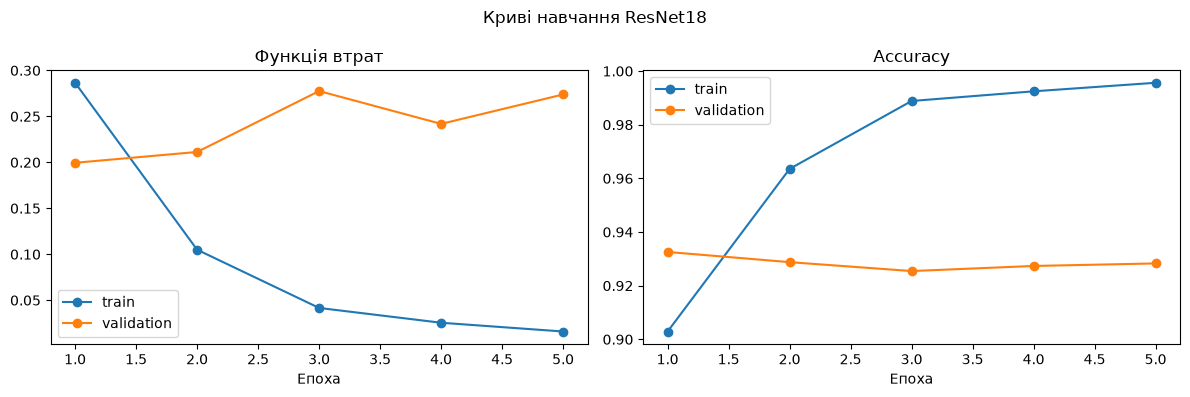

In [7]:
def plot_history(history, title):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history['train_loss'], 'o-', label='train')
    axes[0].plot(epochs, history['val_loss'], 'o-', label='validation')
    axes[0].set_title('Функція втрат')
    axes[1].plot(epochs, history['train_acc'], 'o-', label='train')
    axes[1].plot(epochs, history['val_acc'], 'o-', label='validation')
    axes[1].set_title('Accuracy')
    for ax in axes:
        ax.set_xlabel('Епоха')
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(history, 'Криві навчання ResNet18')

Найкращий результат на валідації модель показала вже після першої епохи: accuracy 0.933. Далі точність на навчальних даних росте майже до 1.0, а на валідації не росте, і валідаційна помилка навіть збільшується. Це означає, що модель почала перенавчатися. Тому я зберігаю модель саме з першої епохи.

## 7. Оцінка моделі

Метрики:
- accuracy: частка правильно визначених фото. Класи в наборі майже однакові за розміром, тому ця метрика тут добре показує якість;
- F1-score (macro): для кожного класу враховує і пропущені фото цього класу, і чужі фото, помилково віднесені до нього, а потім усереднює по класах. Так слабкий клас не сховається за сильними.

Для обох метрик у завданні є орієнтовні межі.

In [8]:
y_val, val_pred = predict(model, val_loader)
y_test, test_pred = predict(model, test_loader)
for name, yt, yp in [('validation', y_val, val_pred), ('test', y_test, test_pred)]:
    print(f'{name}: accuracy {accuracy_score(yt, yp):.3f}, F1 (macro) {f1_score(yt, yp, average="macro"):.3f}')
print()
print('Звіт по класах на тесті:')
print(classification_report(y_test, test_pred, target_names=CLASSES, digits=3))

validation: accuracy 0.933, F1 (macro) 0.933
test: accuracy 0.928, F1 (macro) 0.929

Звіт по класах на тесті:
              precision    recall  f1-score   support

   buildings      0.960     0.881     0.919       437
      forest      0.985     0.989     0.987       474
     glacier      0.924     0.841     0.881       553
    mountain      0.869     0.907     0.887       525
         sea      0.935     0.990     0.962       510
      street      0.908     0.964     0.935       501

    accuracy                          0.928      3000
   macro avg      0.930     0.929     0.929      3000
weighted avg      0.929     0.928     0.927      3000



На валідації accuracy 0.933 і F1 0.933, на тесті accuracy 0.928 і F1 0.929. Це в межах орієнтиру із завдання для transfer learning: accuracy від 90 до 97%, F1 від 0.89 до 0.96. Результати на валідації і тесті майже однакові, тобто модель однаково працює на фото, яких не бачила.

Найлегше модель розпізнає forest (F1 0.987) і sea (0.962). Найважче їй даються glacier (0.881) і mountain (0.887).

## 8. Аналіз результатів

Матриці помилок показують фактичні і передбачені класи на навчальному, валідаційному і тестовому наборах. По рядках фактичний клас, по стовпцях прогноз моделі.

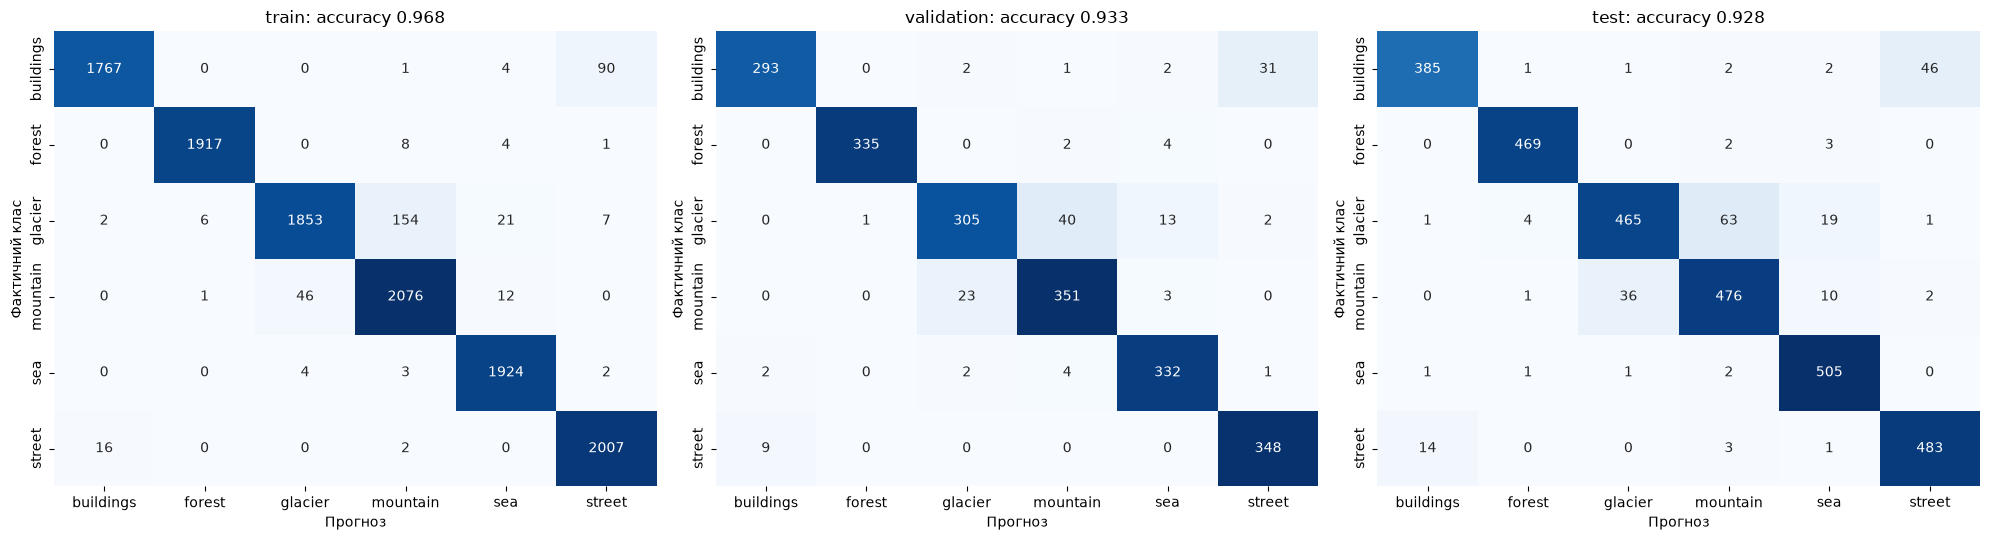

In [9]:
y_train, train_pred = predict(model, train_eval_loader)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (name, yt, yp) in zip(axes, [('train', y_train, train_pred),
                                     ('validation', y_val, val_pred),
                                     ('test', y_test, test_pred)]):
    sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f'{name}: accuracy {accuracy_score(yt, yp):.3f}')
    ax.set_xlabel('Прогноз')
    ax.set_ylabel('Фактичний клас')
plt.tight_layout()
plt.show()

In [10]:
errors = pd.DataFrame({'фактичний': np.array(CLASSES)[y_test], 'прогноз': np.array(CLASSES)[test_pred]})
errors = errors[errors['фактичний'] != errors['прогноз']]
print('Помилок на тесті:', len(errors), 'з', len(y_test))
errors.value_counts().head(6).rename('кількість').to_frame()

Помилок на тесті: 217 з 3000


,,кількість
фактичний,прогноз,
glacier,mountain,63
buildings,street,46
mountain,glacier,36
glacier,sea,19
street,buildings,14
mountain,sea,10


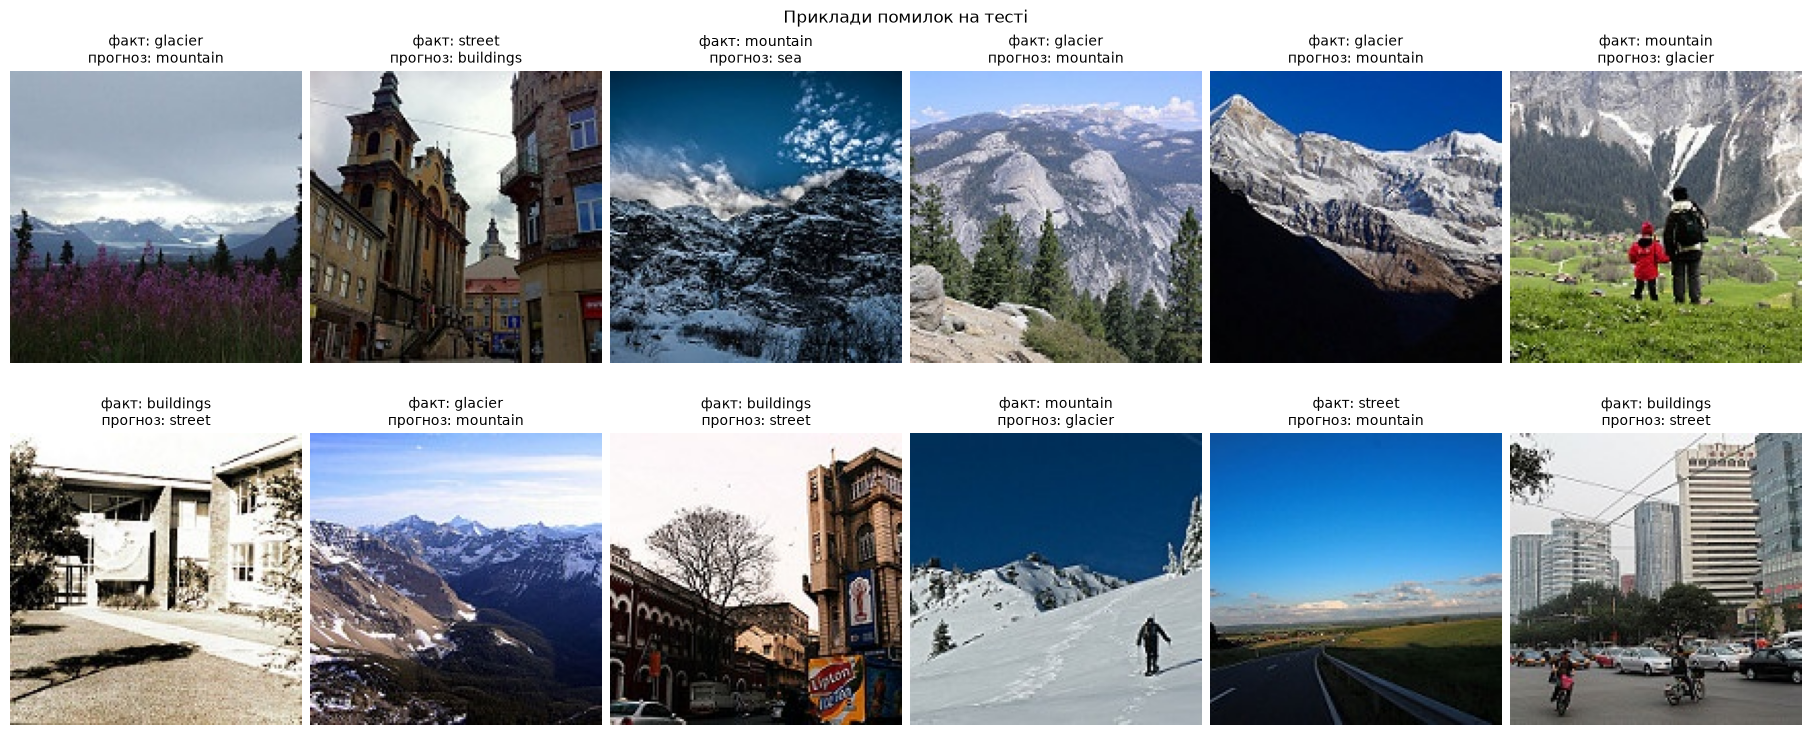

In [11]:
wrong = np.where(y_test != test_pred)[0]
sample = np.random.default_rng(SEED).choice(wrong, 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(18, 7.5), layout='constrained')
for ax, i in zip(axes.ravel(), sample):
    ax.imshow(Image.open(test_ds.samples[i][0]))
    ax.set_title(f'факт: {CLASSES[y_test[i]]}\nпрогноз: {CLASSES[test_pred[i]]}', fontsize=10)
    ax.axis('off')
fig.suptitle('Приклади помилок на тесті')
plt.show()

На всіх трьох наборах помилки однакові за типом, змінюється лише їхня кількість. Найчастіше модель плутає glacier і mountain (99 зі 217 помилок на тесті) та buildings і street (60 помилок). Ці класи схожі між собою: на фото льодовика майже завжди є гори, а на фото вулиці є будинки. Навіть на навчальних даних модель плутає ті самі пари.

На прикладах видно, що багато таких фото неоднозначні. Наприклад, на одному знімку люди стоять на зеленому лузі на тлі гір, а позначений він як mountain. Тут і людині важко вибрати один клас.

## 9. Покращення моделі

Я пробую три інші варіанти і порівнюю їх з основною моделлю за F1 на валідації:
1. заморожена ResNet18: навчається лише останній шар, решта ваг не змінюється. Тут швидкість навчання 0.001, бо вчиться тільки один шар;
2. та сама модель, що й основна, але з аугментацією: випадкове віддзеркалення по горизонталі і невеликий поворот. Природні сцени виглядають природно і віддзеркаленими, тож це додає різноманітності без шкоди;
3. інша архітектура: проста згорткова мережа, яку я навчаю з нуля (варіант A із завдання). У ній чотири блоки із шарів Conv2d, ReLU і MaxPool2d, а потім два шари Linear. Вона нічого не знає наперед, тому їй потрібні більша швидкість навчання (0.001) і більше епох (10).

In [12]:
frozen = make_model(freeze_backbone=True)
history_frozen = train_model(frozen, 'resnet18_frozen', lr=1e-3)

Епоха 1: train loss 0.570, train acc 0.822, val loss 0.341, val acc 0.887, val F1 0.889 (40 с)


Епоха 2: train loss 0.316, train acc 0.895, val loss 0.303, val acc 0.896, val F1 0.897 (43 с)


Епоха 3: train loss 0.283, train acc 0.902, val loss 0.275, val acc 0.907, val F1 0.909 (35 с)


Епоха 4: train loss 0.264, train acc 0.906, val loss 0.269, val acc 0.908, val F1 0.909 (35 с)


Епоха 5: train loss 0.259, train acc 0.908, val loss 0.271, val acc 0.908, val F1 0.909 (39 с)


Найкращий val F1: 0.909, модель збережено в checkpoints/resnet18_frozen.pt


In [13]:
aug_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
aug_loader = make_loader(Subset(datasets.ImageFolder(TRAIN_DIR, aug_tf), train_idx), shuffle=True)

torch.manual_seed(SEED)
augmented = make_model()
history_aug = train_model(augmented, 'resnet18_aug', lr=1e-4, loader=aug_loader)

Епоха 1: train loss 0.308, train acc 0.896, val loss 0.194, val acc 0.934, val F1 0.935 (106 с)


Епоха 2: train loss 0.168, train acc 0.940, val loss 0.202, val acc 0.930, val F1 0.931 (93 с)


Епоха 3: train loss 0.128, train acc 0.955, val loss 0.246, val acc 0.927, val F1 0.928 (88 с)


Епоха 4: train loss 0.102, train acc 0.962, val loss 0.219, val acc 0.932, val F1 0.933 (93 с)


Епоха 5: train loss 0.075, train acc 0.976, val loss 0.240, val acc 0.926, val F1 0.927 (88 с)
Найкращий val F1: 0.935, модель збережено в checkpoints/resnet18_aug.pt


In [14]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        blocks = []
        channels = [3, 32, 64, 128, 128]
        for c_in, c_out in zip(channels[:-1], channels[1:]):
            blocks += [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*blocks)  # 224 -> 112 -> 56 -> 28 -> 14
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 14 * 14, 128), nn.ReLU(),
                                        nn.Linear(128, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(SEED)
simple_cnn = SimpleCNN(len(CLASSES)).to(DEVICE)
history_cnn = train_model(simple_cnn, 'simple_cnn', lr=1e-3, epochs=10)

Епоха 1: train loss 0.977, train acc 0.620, val loss 0.704, val acc 0.764, val F1 0.764 (50 с)


Епоха 2: train loss 0.616, train acc 0.774, val loss 0.589, val acc 0.796, val F1 0.797 (49 с)


Епоха 3: train loss 0.490, train acc 0.819, val loss 0.539, val acc 0.820, val F1 0.821 (50 с)


Епоха 4: train loss 0.399, train acc 0.853, val loss 0.540, val acc 0.824, val F1 0.826 (56 с)


Епоха 5: train loss 0.306, train acc 0.887, val loss 0.534, val acc 0.832, val F1 0.832 (51 с)


Епоха 6: train loss 0.226, train acc 0.918, val loss 0.636, val acc 0.830, val F1 0.830 (49 с)


Епоха 7: train loss 0.154, train acc 0.946, val loss 0.657, val acc 0.847, val F1 0.847 (48 с)


Епоха 8: train loss 0.101, train acc 0.964, val loss 0.737, val acc 0.823, val F1 0.824 (52 с)


Епоха 9: train loss 0.072, train acc 0.976, val loss 0.943, val acc 0.816, val F1 0.817 (53 с)


Епоха 10: train loss 0.076, train acc 0.975, val loss 0.874, val acc 0.826, val F1 0.826 (56 с)
Найкращий val F1: 0.847, модель збережено в checkpoints/simple_cnn.pt


In [15]:
variants = {'основна (ResNet18, вся мережа)': model,
            'заморожена ResNet18': frozen,
            'ResNet18 з аугментацією': augmented,
            'проста CNN з нуля': simple_cnn}

rows = []
for name, m in variants.items():
    yv, pv = predict(m, val_loader)
    yt, pt = predict(m, test_loader)
    rows.append({'модель': name,
                 'val accuracy': accuracy_score(yv, pv), 'val F1': f1_score(yv, pv, average='macro'),
                 'test accuracy': accuracy_score(yt, pt), 'test F1': f1_score(yt, pt, average='macro')})
comparison = pd.DataFrame(rows).sort_values('val F1', ascending=False).reset_index(drop=True).round(3)
comparison

,модель,val accuracy,val F1,test accuracy,test F1
0,ResNet18 з аугментацією,0.934,0.935,0.930,0.931
1,"основна (ResNet18, вся мережа)",0.933,0.933,0.928,0.929
2,заморожена ResNet18,0.908,0.909,0.906,0.907
3,проста CNN з нуля,0.847,0.847,0.836,0.836


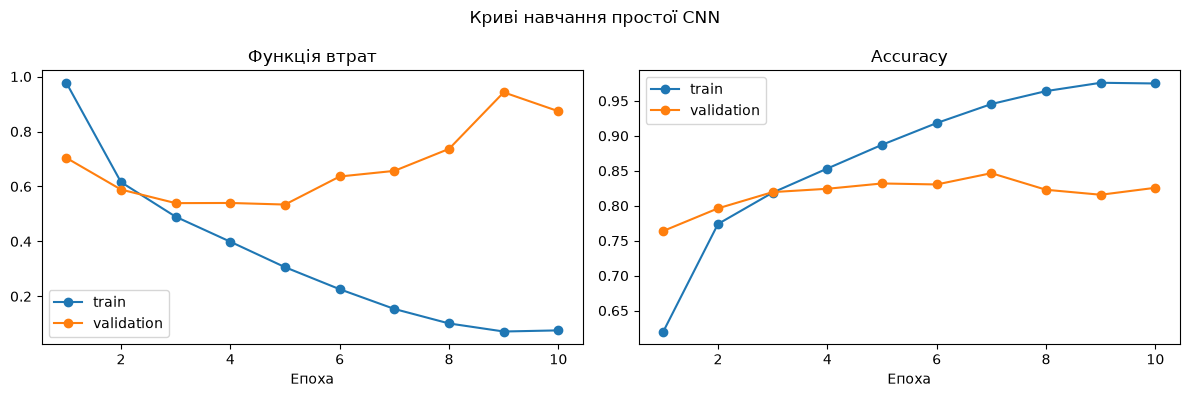

Найкраща модель на валідації: ResNet18 з аугментацією


In [16]:
plot_history(history_cnn, 'Криві навчання простої CNN')
print('Найкраща модель на валідації:', comparison.loc[0, 'модель'])

Заморожена модель навчається вдвічі швидше, але дає гірший результат: F1 на валідації 0.909 проти 0.933. Отже, корисно доналаштовувати всю мережу, а не тільки останній шар.

Аугментація дала невеликий виграш: F1 на валідації 0.935 проти 0.933, на тесті 0.931 проти 0.929. Різниця маленька, але модель з аугментацією менше перенавчається: точність на навчальних даних на 5 епосі 0.976, а не 0.996.

Проста CNN з нуля досягла F1 0.847 на валідації і accuracy 0.836, F1 0.836 на тесті. Це відповідає орієнтиру із завдання для простої мережі (accuracy від 75 до 85%, F1 від 0.73 до 0.83), але на 9 пунктів гірше за ResNet18. Найкращий результат вона показала на 7 епосі, а далі почала перенавчатися. Своїх ознак їй не вистачає, бо вона вчиться лише на 12 тисячах фото, а ResNet18 уже бачила мільйон зображень ImageNet.

Як фінальну я беру ResNet18 з аугментацією, бо вона найкраща на валідації.

## 10. Висновки

- Transfer learning з ResNet18 добре підходить для цієї задачі. Фінальна модель (ResNet18 з аугментацією) на тесті має accuracy 0.930 і F1 0.931, це в межах очікуваного результату.
- Проста CNN з нуля дає accuracy 0.836 на тесті. Для мережі, яку вчили з нуля, це нормально, але попередньо навчена модель помітно краща.
- Попередньо навчена мережа вчиться дуже швидко: найкращий результат уже після першої епохи, а далі вона перенавчається. Тому збереження найкращої за валідацією моделі тут обов'язкове.
- Більшість помилок припадає на дві пари схожих класів: glacier і mountain, buildings і street. Частина таких фото неоднозначна навіть для людини.

Що можна покращити:
- зменшувати швидкість навчання з кожною епохою, щоб модель не перенавчалася після першої епохи;
- додати сильнішу аугментацію: випадкові обрізання, зміну яскравості і кольору;
- для простої CNN додати Dropout і BatchNorm, щоб вона менше перенавчалася;
- спробувати більшу попередньо навчену мережу, наприклад ResNet50 або EfficientNet;
- перевірити сумнівні мітки в даних і виправити їх;
- усереднювати прогнози кількох моделей.